# TP4 — ACP, k-means, classification hiérarchique (corrigé)
**CNFSDP — Introduction au Machine Learning** · L3 S5 · 2026-2027 · Rois Céti DIMBAMBA · chapitre 4 · 45 min en salle

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rdimbamba/ml-cnfsdp/blob/main/notebooks/corriges/TP4_corrige.ipynb)

Partie A : ACP à la main puis indice de richesse. Partie B : k-means et choix du nombre de groupes. Partie C : CAH et forêt d'isolement.
Les ménages sont **fictifs** : ils sont simulés au format des biens relevés par les enquêtes DHS, ce qui permet de connaître la « vraie » richesse et de juger l'indice. Aucun téléchargement n'est nécessaire.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
VERT, OR, GRIS = "#126B2A", "#B8860B", "#8A8A8A"   # couleurs du cours


Fonction de simulation des ménages (à exécuter sans la modifier) :

In [2]:
def simuler_menages(n=2000, graine=0):
    """Ménages fictifs au format des biens DHS : 1 = le ménage possède le bien."""
    rng = np.random.default_rng(graine)
    urbain = rng.random(n) < 0.4
    richesse = rng.standard_normal(n) + 1.2 * urbain            # richesse latente (inobservée)
    sig = lambda t: 1 / (1 + np.exp(-t))
    biens = {  # (constante, effet richesse, effet urbain)
        "electricite": (-0.5, 2.0, 1.5), "eau_courante": (-1.5, 1.8, 1.5), "toilettes": (-1.0, 1.6, 0.8),
        "sol_fini": (-0.3, 1.8, 0.8), "radio": (0.3, 0.8, 0.0), "television": (-1.5, 2.2, 0.8),
        "refrigerateur": (-2.8, 2.2, 0.5), "telephone": (1.0, 1.5, 0.5), "moto": (-1.5, 0.8, -0.5),
        "voiture": (-4.5, 2.0, 0.3), "terre_agricole": (0.8, -0.3, -2.5), "betail": (0.0, -0.2, -2.0)}
    df = pd.DataFrame({b: (rng.random(n) < sig(a + r * richesse + u * urbain)).astype(int)
                       for b, (a, r, u) in biens.items()})
    return df, richesse, urbain

biens, richesse, urbain = simuler_menages()
biens.head()

,electricite,eau_courante,toilettes,sol_fini,radio,television,refrigerateur,telephone,moto,voiture,terre_agricole,betail
0,1,1,1,1,1,1,1,1,1,0,0,0
1,1,0,0,1,1,1,0,1,0,0,0,0
2,1,0,1,1,1,0,0,1,0,0,0,0
3,1,1,1,1,0,1,1,1,0,0,0,0
4,1,1,1,1,1,0,0,1,0,0,1,1


## Partie A — Analyse en composantes principales
### Question 1 — ACP à la main
Quatre ménages, scores centrés de logement et d'équipement : $(-2,-1)$, $(-1,-2)$, $(1,2)$, $(2,1)$. Calculer $S=\frac14X^\top X$, ses valeurs et vecteurs propres (`np.linalg.eigh`), puis tracer $u^\top Su$ pour $u=(\cos\theta,\sin\theta)$, $\theta\in[0,180°]$. Retrouver le maximum $4{,}5$ en $45°$ et la part d'inertie de $90\,\%$.

[[2.5 2. ]
 [2.  2.5]]
valeurs propres : [0.5 4.5] | axe 1 : [0.707 0.707]


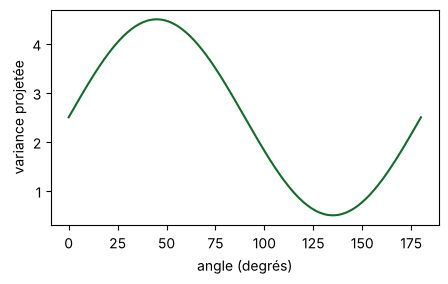

maximum 4.5 en 45 degrés | part : 0.9


In [3]:
X4 = np.array([[-2, -1], [-1, -2], [1, 2], [2, 1]], float)
S = X4.T @ X4 / 4
lam, U = np.linalg.eigh(S)                     # valeurs propres croissantes
print(S); print("valeurs propres :", lam, "| axe 1 :", U[:, -1].round(3))
theta = np.radians(np.arange(0, 181))
var = [np.array([np.cos(t), np.sin(t)]) @ S @ np.array([np.cos(t), np.sin(t)]) for t in theta]
plt.figure(figsize=(5, 2.8)); plt.plot(np.degrees(theta), var, color=VERT)
plt.xlabel("angle (degrés)"); plt.ylabel("variance projetée"); plt.show()
print("maximum", round(max(var), 3), "en", int(np.degrees(theta[np.argmax(var)])), "degrés | part :", lam[-1] / lam.sum())

### Question 2 — L'indice de richesse
Faire une ACP normée des 12 biens (`StandardScaler` puis `PCA`). Afficher l'éboulis des valeurs propres et les corrélations de chaque bien avec les deux premières composantes ($\sqrt{\lambda_k}\,u_{jk}$). Construire l'indice de richesse (composante 1, orientée pour croître avec l'électricité), ses quintiles, et le taux d'équipement en réfrigérateur par quintile. Comparer l'indice à la richesse cachée `richesse`.

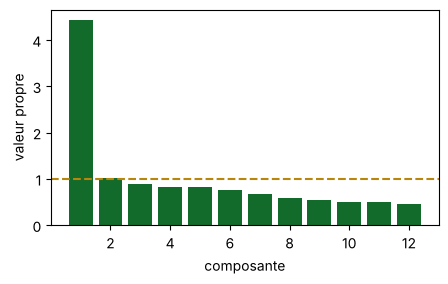

parts d'inertie : [0.369 0.085 0.074]
                axe 1  axe 2
electricite      0.74  -0.18
eau_courante     0.75  -0.08
toilettes        0.70   0.05
sol_fini         0.69  -0.07
radio            0.42   0.16
television       0.75   0.04
refrigerateur    0.69   0.19
telephone        0.59  -0.06
moto             0.34   0.65
voiture          0.50   0.36
terre_agricole  -0.52   0.35
betail          -0.41   0.48


réfrigérateur par quintile : [0.01 0.04 0.17 0.48 0.91]
corrélation avec la richesse cachée : 0.895


In [4]:
Z = StandardScaler().fit_transform(biens)
acp = PCA().fit(Z)
lam = acp.explained_variance_
plt.figure(figsize=(5, 2.8)); plt.bar(range(1, 13), lam, color=VERT); plt.axhline(1, color=OR, ls="--")
plt.xlabel("composante"); plt.ylabel("valeur propre"); plt.show()
print("parts d'inertie :", acp.explained_variance_ratio_[:3].round(3))

corr = pd.DataFrame(acp.components_[:2].T * np.sqrt(lam[:2]), index=biens.columns, columns=["axe 1", "axe 2"])
print(corr.round(2))

indice = acp.transform(Z)[:, 0]
if np.corrcoef(indice, biens["electricite"])[0, 1] < 0:
    indice = -indice
quintile = pd.qcut(indice, 5, labels=False) + 1
print("réfrigérateur par quintile :", biens.groupby(quintile)["refrigerateur"].mean().round(2).values)
print("corrélation avec la richesse cachée :", round(np.corrcoef(indice, richesse)[0, 1], 3))

**À commenter :** combien d'axes garder (règle $\lambda>1$) ? Que représente l'axe 1 ? Quels biens tirent l'axe 2 ?

## Partie B — k-means
### Question 3 — L'algorithme de Lloyd en NumPy
Programmer k-means ($k=2$) pour les revenus $1, 2, 4, 6, 9, 12$ : affectation au centre le plus proche, puis centres = moyennes, jusqu'à stabilité, en affichant $W$ à chaque itération. Partir des centres $1$ et $2$, puis $3$ et $11$. Quelle partition a la plus petite inertie ?

In [5]:
x = np.array([1, 2, 4, 6, 9, 12.])

def lloyd(x, centres):
    centres = np.array(centres, float)
    while True:
        groupe = np.argmin(np.abs(x[:, None] - centres[None, :]), axis=1)   # affectation
        W = sum(((x[groupe == j] - centres[j]) ** 2).sum() for j in range(len(centres)))
        print("centres", centres.round(2), "| groupes", [x[groupe == j].tolist() for j in range(len(centres))], "| W =", round(W, 2))
        nouveaux = np.array([x[groupe == j].mean() for j in range(len(centres))])   # mise à jour
        if np.allclose(nouveaux, centres):
            return groupe, W
        centres = nouveaux

lloyd(x, [1, 2]); print()
lloyd(x, [3, 11])

centres [1. 2.] | groupes [[1.0], [2.0, 4.0, 6.0, 9.0, 12.0]] | W = 169.0
centres [1.  6.6] | groupes [[1.0, 2.0], [4.0, 6.0, 9.0, 12.0]] | W = 43.04
centres [1.5  7.75] | groupes [[1.0, 2.0, 4.0], [6.0, 9.0, 12.0]] | W = 29.44
centres [2.33 9.  ] | groupes [[1.0, 2.0, 4.0], [6.0, 9.0, 12.0]] | W = 22.67

centres [ 3. 11.] | groupes [[1.0, 2.0, 4.0, 6.0], [9.0, 12.0]] | W = 20.0
centres [ 3.25 10.5 ] | groupes [[1.0, 2.0, 4.0, 6.0], [9.0, 12.0]] | W = 19.25


(array([0, 0, 0, 0, 1, 1]), np.float64(19.25))

### Question 4 — Combien de groupes de ménages ?
Sur les deux premières composantes, calculer l'inertie intra $W(k)$ et la silhouette moyenne de `KMeans(n_init=10)` pour $k=2,\dots,8$ ; tracer les deux courbes. Retenir $k=3$, puis décrire chaque groupe par son effectif et ses taux d'équipement (électricité, voiture, bétail).

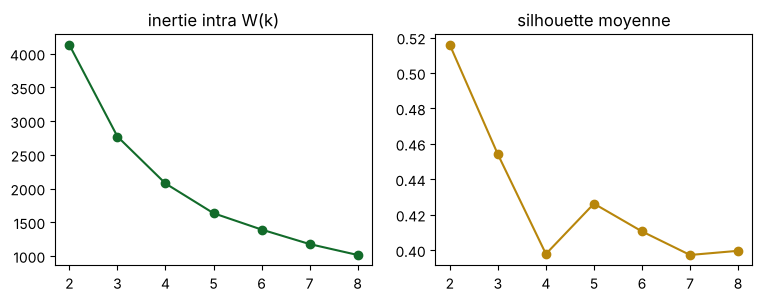

   electricite  voiture  betail  effectif
0         0.96     0.55    0.23       415
1         0.21     0.01    0.55       870
2         0.90     0.03    0.14       715


In [6]:
C = PCA(n_components=2).fit_transform(Z)
ks = range(2, 9); W, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(C)
    W.append(km.inertia_); sil.append(silhouette_score(C, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(ks, W, color=VERT, marker="o"); axes[0].set_title("inertie intra W(k)")
axes[1].plot(ks, sil, color=OR, marker="o"); axes[1].set_title("silhouette moyenne"); plt.show()

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(C)
profil = biens.groupby(km.labels_)[["electricite", "voiture", "betail"]].mean().round(2)
profil["effectif"] = pd.Series(km.labels_).value_counts().sort_index()
print(profil)

## Partie C — Classification hiérarchique et forêt d'isolement
### Question 5 — CAH de Ward sur les six revenus
Avec `linkage(x.reshape(-1, 1), method="ward")`, tracer le dendrogramme. scipy affiche une hauteur $h=\sqrt{2\Delta}$ : retrouver les hausses d'inertie $\Delta=h^2/2$ du cours ($0{,}5$ ; $2$ ; $4{,}5$ ; $12{,}25$ ; $70{,}08$). Pour la partition en 2 groupes, vérifier $T=W+B$.

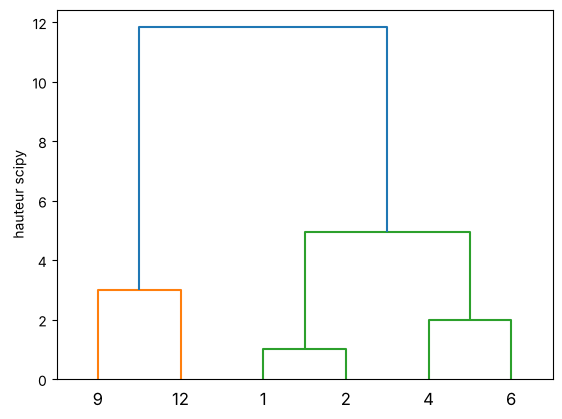

hausses d'inertie : [ 0.5   2.    4.5  12.25 70.08]
T = 89.33 | W = 19.25 | B = 70.08 | W + B = 89.33 | B/T = 78%


In [7]:
L = linkage(x.reshape(-1, 1), method="ward")
dendrogram(L, labels=[str(int(v)) for v in x]); plt.ylabel("hauteur scipy"); plt.show()
print("hausses d'inertie :", (L[:, 2] ** 2 / 2).round(2))

groupes = [x[x <= 6], x[x > 6]]
T = ((x - x.mean()) ** 2).sum()
W = sum(((g - g.mean()) ** 2).sum() for g in groupes)
B = sum(len(g) * (g.mean() - x.mean()) ** 2 for g in groupes)
print(f"T = {T:.2f} | W = {W:.2f} | B = {B:.2f} | W + B = {W + B:.2f} | B/T = {B / T:.0%}")

### Question 6 — Les ménages atypiques
Ajuster `IsolationForest(contamination=0.01)` sur les biens standardisés. Combien de ménages sont signalés ? Comparer leurs taux d'équipement à ceux de l'ensemble des ménages : qu'ont-ils d'inhabituel ?

In [8]:
iso = IsolationForest(contamination=0.01, random_state=0).fit(Z)
atypiques = biens[iso.predict(Z) == -1]
print(len(atypiques), "ménages atypiques")
print(pd.DataFrame({"atypiques": atypiques.mean(), "tous": biens.mean()}).round(2))

20 ménages atypiques
                atypiques  tous
electricite          0.50  0.61
eau_courante         0.25  0.49
toilettes            0.45  0.50
sol_fini             0.55  0.61
radio                0.50  0.64
television           0.55  0.48
refrigerateur        0.65  0.32
telephone            0.50  0.76
moto                 0.75  0.25
voiture              0.40  0.13
terre_agricole       0.55  0.46
betail               0.75  0.34


**Conclusion attendue.** La première composante résume l'équipement des ménages et suit de près la richesse cachée : c'est le principe de l'indice de richesse DHS. Lloyd peut s'arrêter sur un minimum local (W = 22,67 contre 19,25) ; la CAH de Ward retrouve ici la meilleure partition. Les ménages atypiques combinent des biens rarement possédés ensemble.